# Lifecycle-Timed Churn Retention for Company A: a Proof of Concept
**GCI World 2026 Winter Final Assignment (Matsuo-Iwasawa Lab, The University of Tokyo)**

Every number and chart in the presentation comes from this notebook.

**Business question.** Company A is a US wireless carrier with ~100,000 customers in the sample and no in-house ML.
Which customers are about to leave, *when* are they most at risk, and how should Company A spend a limited retention
budget so that the campaign makes money?

**Answer in one line.** Churn spikes at two predictable moments of the customer lifecycle (about 10 months after
sign-up and about 300 days after the last handset change). A gradient-boosting model ranks customers by risk
(ROC-AUC about 0.70), and ranking them by *expected profit* instead of risk alone turns an unprofitable blanket campaign
into a profitable targeted one.

**Contents**
1. Setup and data loading
2. EDA: what the data says (market context is in the slides)
3. Problem definition (target, ML task, metric)
4. Feature engineering
5. Models and evaluation (baseline vs improved, 5-fold CV + hold-out)
6. What drives churn (importance and partial dependence)
7. From scores to money: expected-profit targeting, scenarios and sensitivity
8. Export of all numbers used on the slides

*Run time: about 1 hour on a laptop CPU (the random forest and the cross-validated tuning dominate). Set the environment
variable `FAST=1` to skip the hyper-parameter search and shrink the cross-validation (about 10 minutes) for a quick check.*

## 1. Setup and data loading

In [1]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
if os.environ.get("MPLBACKEND") is None and "ipykernel" not in os.sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter

import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, log_loss
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEED = 42
FAST = os.environ.get("FAST", "0") == "1"
N_JOBS = max(1, (os.cpu_count() or 4) - 1)
rng = np.random.default_rng(SEED)

# locate the data folder (works in the course folder layout and on Colab)
for cand in [Path("telecom"), Path("Final Assignment/telecom"), Path("../telecom")]:
    if (cand / "Client.csv").exists():
        DATA = cand
        break
else:
    raise FileNotFoundError("Put the 'telecom' folder next to this notebook (Client.csv, Record.csv).")

OUT = Path("outputs"); FIG = OUT / "figs"; FIG.mkdir(parents=True, exist_ok=True)
R = {}  # every number used on the slides is collected here and exported at the end

# one consistent, projector-friendly style
NAVY, RED, TEAL, GREY, GOLD = "#1F3A5F", "#D1495B", "#2A9D8F", "#8D99AE", "#EDAE49"
plt.rcParams.update({"font.size": 13, "axes.titlesize": 15, "axes.labelsize": 13, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110,
                     "axes.titleweight": "bold", "legend.frameon": False})


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()


client = pd.read_csv(DATA / "Client.csv")
record = pd.read_csv(DATA / "Record.csv")
df = record.merge(client, on="Customer_ID", how="inner", validate="1:1")
y = df["churn"].astype(int).values
print(client.shape, record.shape, "->", df.shape, "| unique customers:", df.Customer_ID.is_unique)
R["n_customers"] = int(len(df)); R["n_columns"] = int(df.shape[1])
R["churn_rate_sample"] = float(y.mean())

(100000, 50) (100000, 51) -> (100000, 100) | unique customers: True


## 2. Exploratory data analysis

### 2.1 Target balance and a warning about the sample
`churn` = the customer left 31-60 days after the observation date. Exactly half of the customers are churners
(49.6%). Real carriers lose roughly 1-3% of customers a month (US postpaid phone churn was 0.9-1.0% per month at the big
three in 2025), so this table is an **over-sampled** extract: churners were deliberately over-represented, which is common
practice when building churn models. Two things follow from this, and we keep them in mind throughout:
* accuracy and predicted probabilities cannot be compared directly with the real population, so we judge the model with
  rank metrics (ROC-AUC, lift) and **re-weight to a realistic base rate** before putting any money figure on it;
* every business number depends on the assumed true monthly churn rate, so we show how it changes with that rate.

churn
0    0.504
1    0.496
Name: proportion, dtype: float64


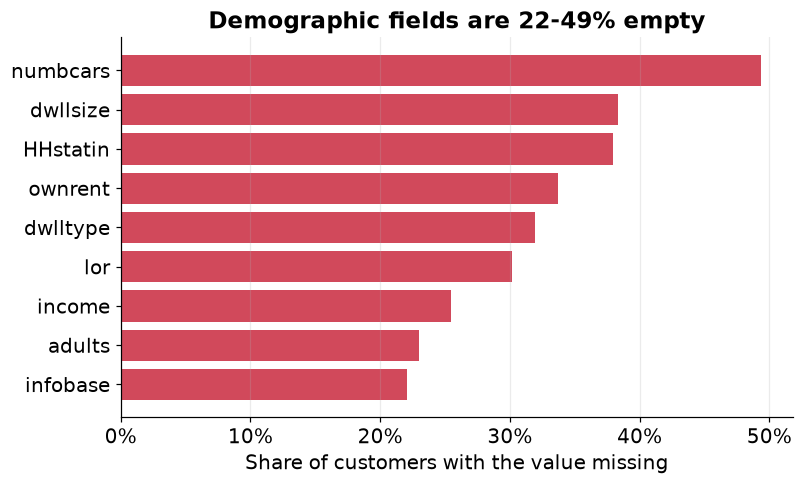

In [2]:
print(df["churn"].value_counts(normalize=True).round(3))
miss = df.isna().mean().sort_values(ascending=False)
R["missing_top"] = {k: float(v) for k, v in miss.head(10).items()}
R["n_cols_missing_over_20pct"] = int((miss > 0.20).sum())

fig, ax = plt.subplots(figsize=(7.5, 4.6))
top = miss.head(9)[::-1]
ax.barh(top.index, top.values, color=[RED if v > 0.2 else GREY for v in top.values])
ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_xlabel("Share of customers with the value missing")
ax.set_title("Demographic fields are 22-49% empty")
ax.grid(axis="y", visible=False)
savefig("fig_missing")

### 2.2 Two lifecycle cliffs
The tutorial suggests looking at tenure (`months`) and equipment age (`eqpdays`). Plotting churn by *single months* and
by *30-day handset-age bins* (instead of 5 equal-sized quantiles, which hide the pattern) reveals sharp steps.

months 5-8 vs 10-12: (0.3306338732253549, 10002) (0.582204081632653, 18375) | eqpdays <300 vs 300-420: (0.3944046485999098, 39926) (0.5849040691545435, 23715)


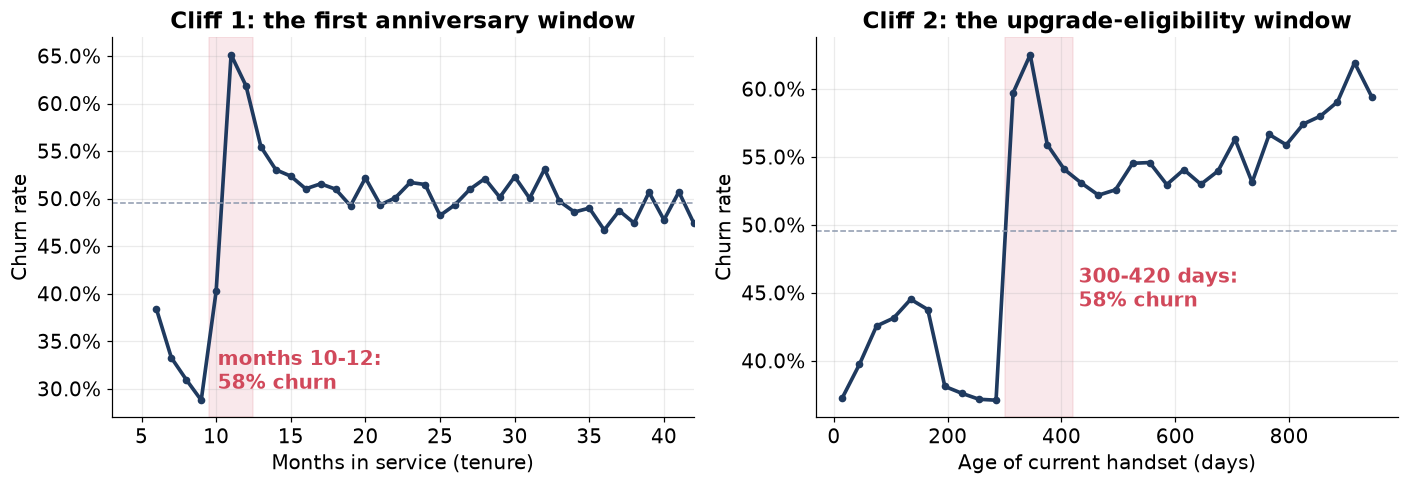

In [3]:
by_m = df.assign(churn=y).groupby("months").churn.agg(["mean", "size"])
by_m = by_m[by_m["size"] >= 200]
eq_bins = np.arange(0, 961, 30)
df["eq_bin"] = pd.cut(df.eqpdays, eq_bins, right=False)
by_e = df.assign(churn=y).groupby("eq_bin", observed=True).churn.agg(["mean", "size"])
by_e["mid"] = [iv.left + 15 for iv in by_e.index]

def seg_mean(mask):
    return float(y[mask].mean()), int(mask.sum())

m_lo = seg_mean((df.months >= 5) & (df.months <= 8))
m_hi = seg_mean((df.months >= 10) & (df.months <= 12))
e_lo = seg_mean(df.eqpdays < 300)
e_hi = seg_mean((df.eqpdays >= 300) & (df.eqpdays < 420))
R["cliff_months"] = {"before_5_8": m_lo, "peak_10_12": m_hi}
R["cliff_eqpdays"] = {"before_lt300": e_lo, "after_300_420": e_hi}
print("months 5-8 vs 10-12:", m_lo, m_hi, "| eqpdays <300 vs 300-420:", e_lo, e_hi)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.plot(by_m.index, by_m["mean"], color=NAVY, lw=2.4, marker="o", ms=4)
ax.axvspan(9.5, 12.5, color=RED, alpha=0.12)
ax.axhline(y.mean(), color=GREY, ls="--", lw=1)
ax.text(10.1, 0.30, "months 10-12:\n%.0f%% churn" % (m_hi[0] * 100), color=RED, fontweight="bold")
ax.set_xlim(3, 42); ax.set_xlabel("Months in service (tenure)"); ax.set_ylabel("Churn rate")
ax.yaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_title("Cliff 1: the first anniversary window")
ax = axes[1]
ax.plot(by_e["mid"], by_e["mean"], color=NAVY, lw=2.4, marker="o", ms=4)
ax.axvspan(300, 420, color=RED, alpha=0.12); ax.axhline(y.mean(), color=GREY, ls="--", lw=1)
ax.text(430, 0.44, "300-420 days:\n%.0f%% churn" % (e_hi[0] * 100), color=RED, fontweight="bold")
ax.set_xlabel("Age of current handset (days)"); ax.set_ylabel("Churn rate")
ax.yaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_title("Cliff 2: the upgrade-eligibility window")
savefig("fig_cliffs")

### 2.3 The two cliffs combined
Ten months is about 300 days, so a customer who has never changed handset reaches *both* cliffs at the same time. A heat-map
of churn by tenure band and handset-age band shows whether the two effects are separate or one group, and the size of each
cell (a retention team needs volume, not only a high rate). What it shows: the 10-12 month, 300-420 day cell (customers who
reach their first anniversary still carrying the original handset) is the hot spot, while the same tenure band with a
*newer* handset churns much less. So the group worth acting on is "first anniversary and no upgrade yet", not two unrelated
windows. One caveat: part of this pattern could come from how the sample was drawn, which is why the proposal starts with a
pilot.

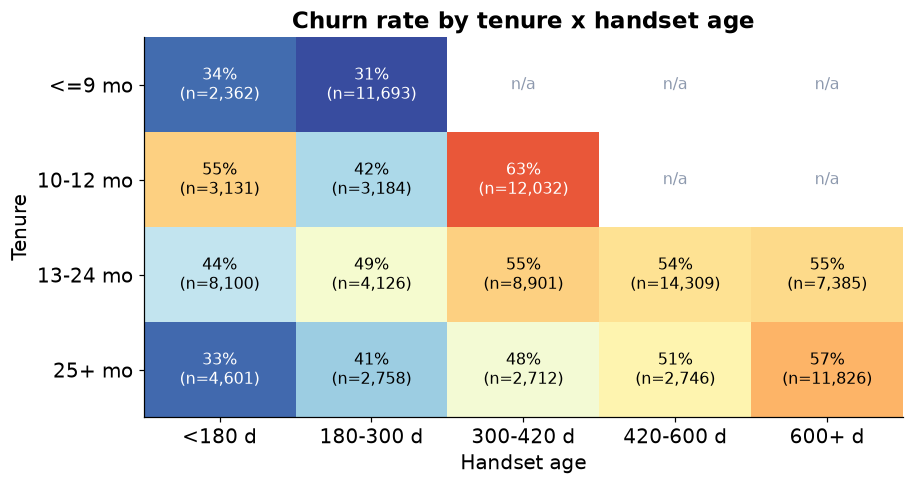

In [4]:
t_bins = [0, 9, 12, 24, 100]; t_lab = ["<=9 mo", "10-12 mo", "13-24 mo", "25+ mo"]
e_bins = [-1, 180, 300, 420, 600, 5000]; e_lab = ["<180 d", "180-300 d", "300-420 d", "420-600 d", "600+ d"]
tmp = pd.DataFrame({"t": pd.cut(df.months, t_bins, labels=t_lab), "e": pd.cut(df.eqpdays, e_bins, labels=e_lab), "y": y})
heat = tmp.pivot_table(index="t", columns="e", values="y", aggfunc="mean", observed=True)
cnt = tmp.pivot_table(index="t", columns="e", values="y", aggfunc="size", observed=True).fillna(0)
heat = heat.reindex(index=t_lab, columns=e_lab); cnt = cnt.reindex(index=t_lab, columns=e_lab).fillna(0)
R["heatmap_rate"] = heat.round(4).to_dict(); R["heatmap_n"] = cnt.to_dict()

fig, ax = plt.subplots(figsize=(8.5, 4.6))
im = ax.imshow(heat.values, cmap="RdYlBu_r", vmin=0.3, vmax=0.7, aspect="auto")
ax.set_xticks(range(len(e_lab))); ax.set_xticklabels(e_lab); ax.set_yticks(range(len(t_lab))); ax.set_yticklabels(t_lab)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        if np.isnan(heat.values[i, j]) or cnt.values[i, j] < 30:
            ax.text(j, i, "n/a", ha="center", va="center", fontsize=10.5, color=GREY); continue
        ax.text(j, i, "%.0f%%\n(n=%s)" % (heat.values[i, j] * 100, f"{int(cnt.values[i, j]):,}"), ha="center", va="center",
                fontsize=10.5, color="white" if heat.values[i, j] > 0.6 or heat.values[i, j] < 0.38 else "black")
ax.set_xlabel("Handset age"); ax.set_ylabel("Tenure"); ax.grid(False)
ax.set_title("Churn rate by tenure x handset age")
savefig("fig_heatmap")

### 2.4 Other early hypotheses
* Falling usage goes with churn (`change_mou`); cheaper handsets churn more; regions differ.
* Customer-care calls and dropped/blocked calls show weaker, mostly one-step relationships (about 6-7 points between the
  lowest and highest group, against 9-17 points for usage change and handset price): network quality is a secondary
  story in this data. (Bins are quantile bins; variables with many identical values, such as zero care calls, give fewer bins.)

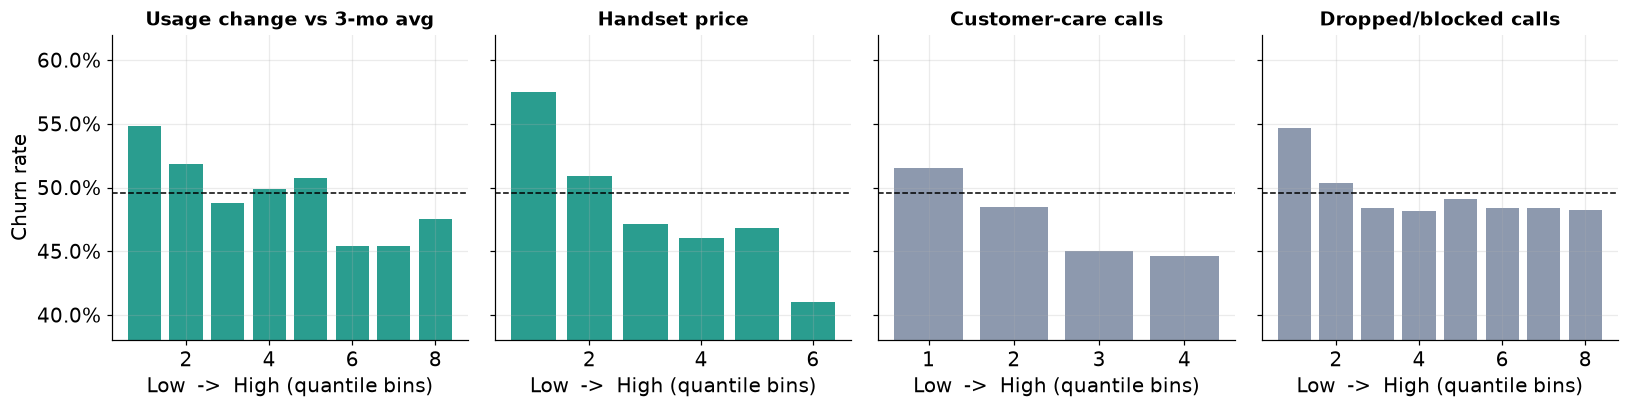

                               mean  size
area                                     
MIDWEST AREA               0.459029  6346
DC/MARYLAND/VIRGINIA AREA  0.460332  6567
OHIO AREA                  0.463755  4580                                    mean  size
area                                         
CALIFORNIA NORTH AREA          0.521055  5913
SOUTH FLORIDA AREA             0.533613  3332
NORTHWEST/ROCKY MOUNTAIN AREA  0.569085  4328


In [5]:
def decile_curve(col, q=8):
    s = pd.qcut(df[col], q, labels=False, duplicates="drop")
    return pd.Series(y).groupby(s.values).mean().values

panel = {"change_mou": "Usage change vs 3-mo avg", "hnd_price": "Handset price", "custcare_Mean": "Customer-care calls",
         "drop_blk_Mean": "Dropped/blocked calls"}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), sharey=True)
spread = {}
for ax, (col, ttl) in zip(axes, panel.items()):
    vals = decile_curve(col)
    ax.bar(range(1, len(vals) + 1), vals, color=TEAL if vals.max() - vals.min() > 0.08 else GREY)
    ax.axhline(y.mean(), color="k", ls="--", lw=1); ax.set_title(ttl, fontsize=12.5); ax.set_ylim(0.38, 0.62)
    ax.set_xlabel("Low  ->  High (quantile bins)"); spread[col] = float(vals.max() - vals.min())
axes[0].set_ylabel("Churn rate"); axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
savefig("fig_other_signals")
R["octile_spread"] = spread

area = df.assign(churn=y).groupby("area").churn.agg(["mean", "size"]).sort_values("mean")
R["area_low"] = [area.index[0], float(area["mean"].iloc[0])]; R["area_high"] = [area.index[-1], float(area["mean"].iloc[-1])]
print(area.head(3), area.tail(3))

## 3. Problem definition
* **Target:** `churn` (leaves in the next 31-60 days). Reason: it is the direct driver of revenue loss, it is observed for
  every customer, and the tutorial's market notes (mature, saturated market; acquisition costs several times retention
  costs) make retention the most valuable lever.
* **ML task:** supervised binary classification that outputs a churn *probability* per customer.
* **Decision the model supports:** who receives a retention contact/offer *this month*.
* **Model metric:** ROC-AUC (rank quality; unaffected by the 50% over-sampling), PR-AUC and top-decile lift for context.
* **Business metric:** expected net profit of the campaign per 100,000 customers, computed after re-weighting to a
  realistic churn rate and using the cost-benefit framework of Verbraken et al. (2013).

## 4. Feature engineering
Ratios that translate the data dictionary into behaviour: usage and revenue **trends** (last 3/6 months vs life-time
average), **failure and drop rates**, handset **age relative to tenure** (has the customer ever upgraded?), overage share
of the bill, handset price relative to the plan price, and how many demographic fields are missing. The two windows found
in the EDA are learned by the trees; we also add an explicit `eq_window` flag for the linear model.

In [6]:
def add_features(d):
    d = d.copy()
    d["eq_to_tenure"] = d.eqpdays / (d.months * 30.4 + 1)
    d["mou_trend3"] = d.avg3mou / (d.avgmou + 1)
    d["mou_trend6"] = d.avg6mou / (d.avgmou + 1)
    d["rev_trend3"] = d.avg3rev / (d.avgrev + 1)
    d["qty_trend3"] = d.avg3qty / (d.avgqty + 1)
    d["fail_rate"] = d.drop_blk_Mean / (d.attempt_Mean + 1)
    d["drop_rate"] = d.drop_vce_Mean / (d.plcd_vce_Mean + 1)
    d["ovr_share"] = d.ovrrev_Mean / (d.rev_Mean.clip(lower=0) + 1)
    d["rev_per_min"] = d.rev_Mean / (d.mou_Mean + 1)
    d["price_to_mrc"] = d.hnd_price / d.totmrc_Mean.clip(lower=1)
    d["cc_rate"] = d.custcare_Mean / (d.attempt_Mean + 1)
    demo = ["numbcars", "dwllsize", "HHstatin", "ownrent", "dwlltype", "lor", "income", "adults", "infobase"]
    d["demo_missing"] = d[demo].isna().sum(axis=1)
    d["phones_per_year"] = d.phones / (d.months / 12 + 0.25)
    d["eq_window"] = ((d.eqpdays >= 300) & (d.eqpdays < 420)).astype(int)
    d["tenure_window"] = ((d.months >= 10) & (d.months <= 12)).astype(int)
    return d.replace([np.inf, -np.inf], np.nan)


X_raw = df.drop(columns=["churn", "Customer_ID", "eq_bin"])
X_fe = add_features(X_raw)
cat_cols = X_fe.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X_fe.columns if c not in cat_cols]
print(len(X_raw.columns), "raw ->", len(X_fe.columns), "features;", len(cat_cols), "categorical")
R["n_features_raw"] = int(X_raw.shape[1]); R["n_features_fe"] = int(X_fe.shape[1])

# gradient-boosting view (native categoricals) and scikit-learn view (strings filled)
X_gb = X_fe.copy()
for c in cat_cols:
    X_gb[c] = X_gb[c].astype("category")
X_gb_raw = X_raw.copy()
for c in cat_cols:
    X_gb_raw[c] = X_gb_raw[c].astype("category")
X_sk = X_fe.copy()
for c in cat_cols:
    X_sk[c] = X_sk[c].astype(object).where(X_sk[c].notna(), "MISSING").astype(str)

# 80% development set (cross-validation) / 20% untouched hold-out
idx = np.arange(len(y))
idx_tr, idx_te = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
ytr, yte = y[idx_tr], y[idx_te]
print("development:", len(idx_tr), "hold-out:", len(idx_te))

98 raw -> 113 features; 21 categorical


development: 80000 hold-out: 20000


## 5. Models and evaluation
Four model families, from simple to flexible, plus a blend:
* **Logistic regression**: a transparent linear baseline, the kind of model a client can audit;
* **Random forest**: bagged trees, a strong default for tabular data;
* **XGBoost** and **LightGBM**: gradient-boosted trees, usually the best choice for mixed numeric and categorical business data.

The *tutorial baseline* (XGBoost with default settings on the raw columns) is reported as the reference.
All hyper-parameters are chosen with cross-validation on the development set only; the hold-out is touched once.

In [7]:
skf = StratifiedKFold(5 if not FAST else 3, shuffle=True, random_state=SEED)
folds = list(skf.split(idx_tr, ytr))


def lift_at(yv, pv, frac=0.10):
    k = int(len(yv) * frac); o = np.argsort(-pv)[:k]
    return float(yv[o].mean() / yv.mean())


def evaluate(name, yv, pv):
    return {"model": name, "auc": float(roc_auc_score(yv, pv)), "pr_auc": float(average_precision_score(yv, pv)),
            "lift10": lift_at(yv, pv), "logloss": float(log_loss(yv, np.clip(pv, 1e-6, 1 - 1e-6)))}


# -- hyper-parameter search (early-stopped CV on the development set) --------------------------------------
tuning = {}
if FAST:
    lgb_params = dict(num_leaves=15, learning_rate=0.05, min_child_samples=50, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.5, reg_lambda=5.0); lgb_rounds = 300
    xgb_params = dict(max_depth=5, learning_rate=0.05, min_child_weight=20, subsample=0.8, colsample_bytree=0.5, reg_lambda=5.0); xgb_rounds = 300
else:
    best = (0, None, None)
    for nl in (15, 31, 63):
        p = dict(objective="binary", metric="auc", num_leaves=nl, learning_rate=0.05, min_child_samples=50, subsample=0.8,
                 subsample_freq=1, colsample_bytree=0.5, reg_lambda=5.0, verbose=-1, num_threads=N_JOBS, seed=SEED)
        cvres = lgb.cv(p, lgb.Dataset(X_gb.iloc[idx_tr], ytr), num_boost_round=1500, folds=folds,
                       callbacks=[lgb.early_stopping(60, verbose=False)])
        key = [k for k in cvres if k.endswith("auc-mean")][0]
        sc, nr = max(cvres[key]), int(np.argmax(cvres[key]) + 1)
        tuning[f"lgb_leaves_{nl}"] = {"cv_auc": float(sc), "rounds": nr}
        print("LightGBM leaves", nl, round(sc, 4), nr, flush=True)
        if sc > best[0]:
            best = (sc, nl, nr)
    lgb_params = dict(num_leaves=best[1], learning_rate=0.05, min_child_samples=50, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.5, reg_lambda=5.0); lgb_rounds = best[2]
    best = (0, None, None)
    for md in (4, 6, 8):
        p = dict(objective="binary:logistic", eval_metric="auc", max_depth=md, learning_rate=0.05, min_child_weight=20, subsample=0.8,
                 colsample_bytree=0.5, reg_lambda=5.0, tree_method="hist", enable_categorical=True, nthread=N_JOBS, seed=SEED)
        dtr = xgb.DMatrix(X_gb.iloc[idx_tr], label=ytr, enable_categorical=True)
        cvres = xgb.cv(p, dtr, num_boost_round=1500, folds=folds, early_stopping_rounds=60, verbose_eval=False)
        sc, nr = float(cvres["test-auc-mean"].max()), int(cvres["test-auc-mean"].values.argmax() + 1)
        tuning[f"xgb_depth_{md}"] = {"cv_auc": sc, "rounds": nr}
        print("XGBoost depth", md, round(sc, 4), nr, flush=True)
        if sc > best[0]:
            best = (sc, md, nr)
    xgb_params = dict(max_depth=best[1], learning_rate=0.05, min_child_weight=20, subsample=0.8, colsample_bytree=0.5, reg_lambda=5.0)
    xgb_rounds = best[2]
R["tuning"] = tuning; R["lgb_params"] = {**lgb_params, "n_estimators": lgb_rounds}; R["xgb_params"] = {**xgb_params, "n_estimators": xgb_rounds}


def make_lr():
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("qt", QuantileTransformer(n_quantiles=200, output_distribution="normal"))]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="MISSING")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=50))]), cat_cols)])
    return Pipeline([("pre", pre), ("lr", LogisticRegression(C=0.05, max_iter=400))])


def make_rf():
    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols)])
    return Pipeline([("pre", pre), ("rf", RandomForestClassifier(n_estimators=60 if FAST else 100, min_samples_leaf=30, max_features=0.3,
                                                                 n_jobs=N_JOBS, random_state=SEED))])


def make_lgb():
    return lgb.LGBMClassifier(n_estimators=lgb_rounds, verbose=-1, n_jobs=N_JOBS, random_state=SEED, **lgb_params)


def make_xgb():
    return xgb.XGBClassifier(n_estimators=xgb_rounds, tree_method="hist", enable_categorical=True, n_jobs=N_JOBS,
                             random_state=SEED, **xgb_params)


def make_xgb_default():  # "tutorial baseline": default XGBoost on the raw columns
    return xgb.XGBClassifier(tree_method="hist", enable_categorical=True, n_jobs=N_JOBS, random_state=SEED)


SPECS = {  # name -> (factory, feature view)
    "Baseline: XGBoost defaults, raw columns": (make_xgb_default, X_gb_raw),
    "Logistic regression": (make_lr, X_sk),
    "Random forest": (make_rf, X_sk),
    "XGBoost (tuned)": (make_xgb, X_gb),
    "LightGBM (tuned)": (make_lgb, X_gb),
}
oof, hold, cv_scores, fitted = {}, {}, {}, {}
for name, (factory, view) in SPECS.items():
    t0 = time.time(); Xv = view.iloc[idx_tr]; o = np.zeros(len(idx_tr)); fold_auc = []
    for tr, va in folds:
        m = factory().fit(Xv.iloc[tr], ytr[tr]); o[va] = m.predict_proba(Xv.iloc[va])[:, 1]; fold_auc.append(roc_auc_score(ytr[va], o[va]))
    m = factory().fit(Xv, ytr); hold[name] = m.predict_proba(view.iloc[idx_te])[:, 1]; oof[name] = o; fitted[name] = m
    cv_scores[name] = (float(np.mean(fold_auc)), float(np.std(fold_auc)))
    print(f"{name:42s} CV AUC {cv_scores[name][0]:.4f} +/- {cv_scores[name][1]:.4f} | hold-out AUC {roc_auc_score(yte, hold[name]):.4f} | {time.time() - t0:.0f}s", flush=True)

# blend of the three strongest, probability-averaged (kept on a probability scale for the money step)
blend_members = ["Logistic regression", "XGBoost (tuned)", "LightGBM (tuned)"]
oof["Blend (LR + XGB + LGBM)"] = np.mean([oof[k] for k in blend_members], axis=0)
hold["Blend (LR + XGB + LGBM)"] = np.mean([hold[k] for k in blend_members], axis=0)
cv_scores["Blend (LR + XGB + LGBM)"] = (float(roc_auc_score(ytr, oof["Blend (LR + XGB + LGBM)"])), float("nan"))

rows = []
for name in oof:
    r = evaluate(name, yte, hold[name]); r["cv_auc"] = cv_scores[name][0]; r["cv_auc_sd"] = cv_scores[name][1]
    r["oof_auc"] = float(roc_auc_score(ytr, oof[name])); rows.append(r)
res = pd.DataFrame(rows).set_index("model")
print(res.round(4))
R["model_table"] = res.round(5).reset_index().to_dict(orient="records")

# feature-engineering ablation (same LightGBM, raw vs engineered features, same hold-out)
m_raw = make_lgb().fit(X_gb_raw.iloc[idx_tr], ytr)
R["ablation_fe"] = {"lgbm_raw_features": float(roc_auc_score(yte, m_raw.predict_proba(X_gb_raw.iloc[idx_te])[:, 1])),
                    "lgbm_engineered_features": float(roc_auc_score(yte, hold["LightGBM (tuned)"]))}
print(R["ablation_fe"])

# final model = best out-of-fold AUC among the candidates (chosen WITHOUT looking at the hold-out)
FINAL = max(oof, key=lambda k: roc_auc_score(ytr, oof[k]))
print("FINAL MODEL:", FINAL)
p_hold, p_oof = hold[FINAL], oof[FINAL]
auc_hold = roc_auc_score(yte, p_hold)
boots = [roc_auc_score(yte[b], p_hold[b]) for b in (rng.integers(0, len(yte), len(yte)) for _ in range(300))]
R["final_model"] = FINAL; R["final_auc_holdout"] = float(auc_hold); R["final_auc_ci"] = [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))]
R["final_lift10"] = lift_at(yte, p_hold, 0.10); R["final_lift5"] = lift_at(yte, p_hold, 0.05); R["final_lift20"] = lift_at(yte, p_hold, 0.20)
R["final_pr_auc"] = float(average_precision_score(yte, p_hold))
R["baseline_auc_holdout"] = float(roc_auc_score(yte, hold["Baseline: XGBoost defaults, raw columns"]))
R["baseline_acc_holdout"] = float(((hold["Baseline: XGBoost defaults, raw columns"] > 0.5) == yte).mean())
R["final_acc_holdout"] = float(((p_hold > 0.5) == yte).mean())
print({k: R[k] for k in ["final_auc_holdout", "final_auc_ci", "final_lift10", "final_acc_holdout", "baseline_acc_holdout"]})

LightGBM leaves 15 0.6986 829


LightGBM leaves 31 0.6982 503


LightGBM leaves 63 0.6976 240


XGBoost depth 4 0.6973 779


XGBoost depth 6 0.6981 516


XGBoost depth 8 0.6964 292


... (5 outputs left out)

                                            auc  pr_auc  lift10  logloss  \
model                                                                      
Baseline: XGBoost defaults, raw columns  0.6778  0.6658  1.5577   0.6473   
Logistic regression                      0.6625  0.6463  1.4891   0.6514   
Random forest                            0.6826  0.6688  1.5749   0.6384   
XGBoost (tuned)                          0.6979  0.6846  1.5890   0.6287   
LightGBM (tuned)                         0.6982  0.6866  1.6102   0.6282   
Blend (LR + XGB + LGBM)                  0.6967  0.6836  1.5960   0.6304   

                                         cv_auc  cv_auc_sd  oof_auc  
model                                                                
Baseline: XGBoost defaults, raw columns  0.6764     0.0053   0.6764  
Logistic regression                      0.6617     0.0037   0.6616  
Random forest                            0.6811     0.0046   0.6810  
XGBoost (tuned)                          

{'lgbm_raw_features': 0.6970693010466731, 'lgbm_engineered_features': 0.6981945881889093}


FINAL MODEL: LightGBM (tuned)


{'final_auc_holdout': 0.6981945881889093, 'final_auc_ci': [0.6912348797695725, 0.7052926763789539], 'final_lift10': 1.6101694915254239, 'final_acc_holdout': 0.6407, 'baseline_acc_holdout': 0.62575}


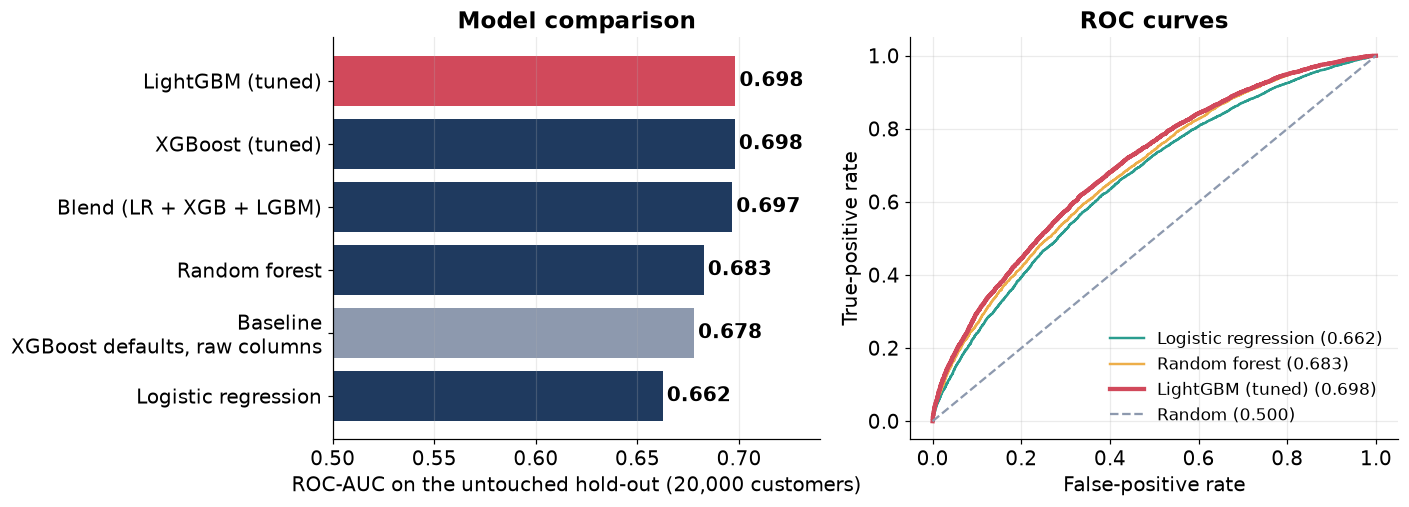

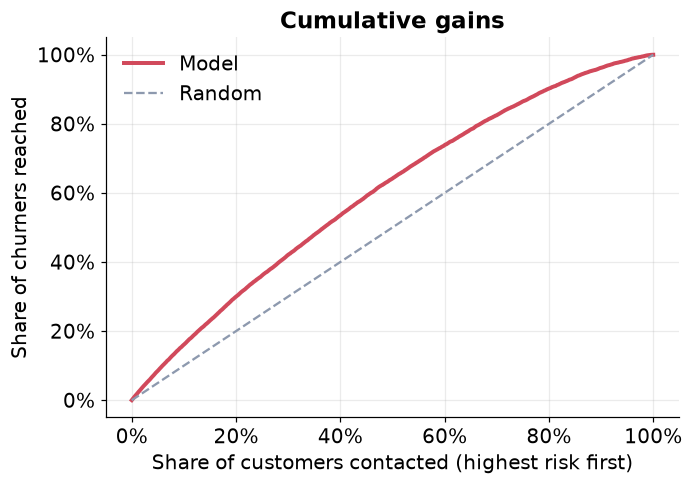

In [8]:
# ROC curves + model comparison chart
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
order = res.sort_values("auc").index
cols = [RED if n == FINAL else (GREY if n.startswith("Baseline") else NAVY) for n in order]
ax.barh([n.replace("Baseline: ", "Baseline\n") for n in order], res.loc[order, "auc"], color=cols)
for i, n in enumerate(order):
    ax.text(res.loc[n, "auc"] + 0.002, i, f"{res.loc[n, 'auc']:.3f}", va="center", fontweight="bold")
ax.set_xlim(0.5, 0.74); ax.set_xlabel("ROC-AUC on the untouched hold-out (20,000 customers)"); ax.set_title("Model comparison"); ax.grid(axis="y", visible=False)
ax = axes[1]
for n, c, lw in [("Logistic regression", TEAL, 1.6), ("Random forest", GOLD, 1.6), (FINAL, RED, 2.8)]:
    fpr, tpr, _ = roc_curve(yte, hold[n]); ax.plot(fpr, tpr, color=c, lw=lw, label=f"{n} ({roc_auc_score(yte, hold[n]):.3f})")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", label="Random (0.500)"); ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate")
ax.set_title("ROC curves"); ax.legend(loc="lower right", fontsize=11)
savefig("fig_models")

# cumulative gains / lift
o = np.argsort(-p_hold); gains = np.cumsum(yte[o]) / yte.sum(); frac = np.arange(1, len(yte) + 1) / len(yte)
fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.plot(frac, gains, color=RED, lw=2.6, label="Model"); ax.plot([0, 1], [0, 1], color=GREY, ls="--", label="Random")
ax.set_xlabel("Share of customers contacted (highest risk first)"); ax.set_ylabel("Share of churners reached")
ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.yaxis.set_major_formatter(PercentFormatter(1.0)); ax.legend(); ax.set_title("Cumulative gains")
savefig("fig_gains")

## 6. What drives churn?
Permutation importance on the hold-out (how much AUC drops when one feature is shuffled) is a model-agnostic check on top
of the tree "gain" importance. Partial dependence shows the *shape* of the effect of the two lifecycle variables.

change_mou     0.0277
months         0.0195
eqpdays        0.0161
totmrc_Mean    0.0124
crclscod       0.0069
rev_per_min    0.0052
uniqsubs       0.0048
mou_trend3     0.0045
area           0.0045
ethnic         0.0039
hnd_price      0.0038
qty_trend3     0.0034
dtype: float64


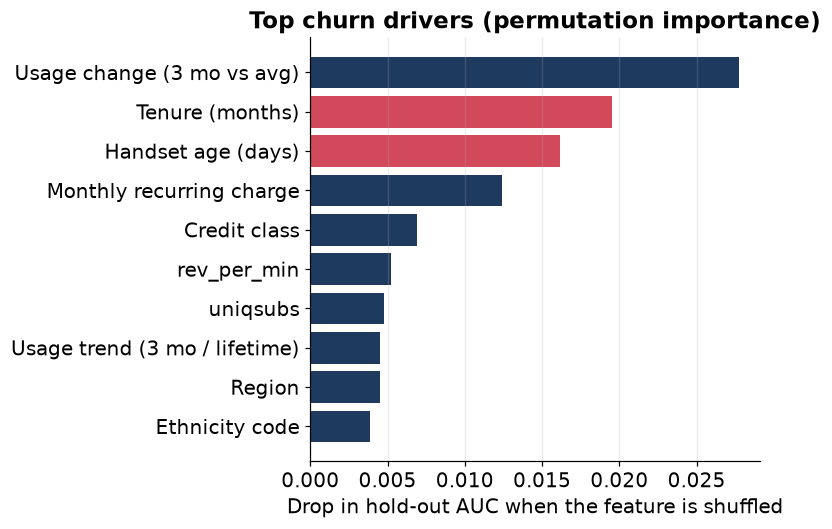

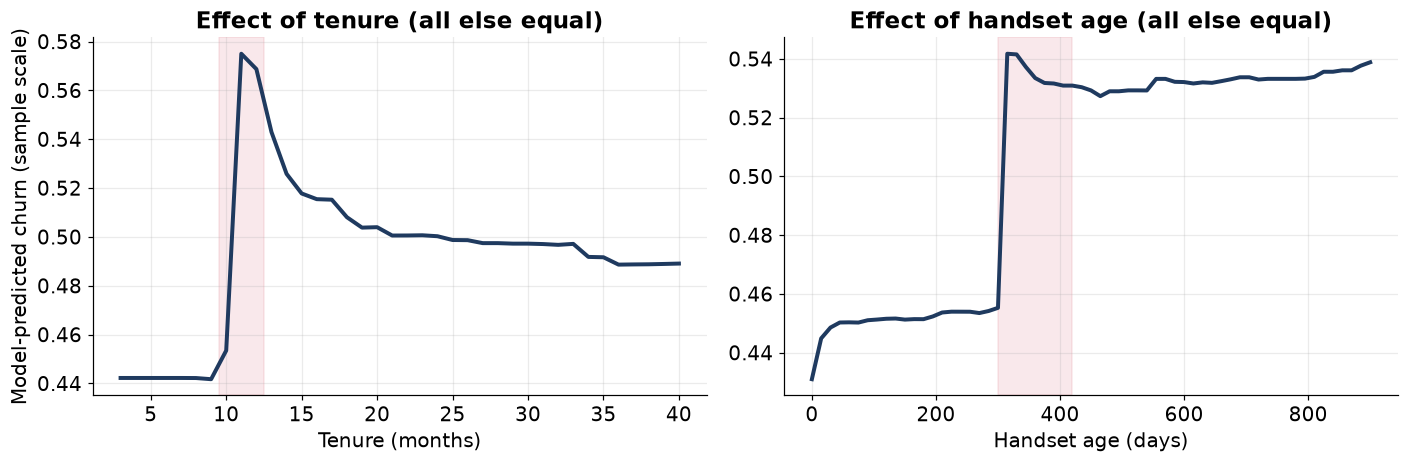

In [9]:
interp_model = fitted["LightGBM (tuned)"]
Xte_gb = X_gb.iloc[idx_te]
pi_res = permutation_importance(interp_model, Xte_gb, yte, scoring="roc_auc", n_repeats=3 if FAST else 5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi_res.importances_mean, X_gb.columns).sort_values(ascending=False)
gain = pd.Series(interp_model.booster_.feature_importance("gain"), X_gb.columns); gain = (gain / gain.sum()).sort_values(ascending=False)
R["perm_importance_top"] = {k: float(v) for k, v in imp.head(12).items()}
R["gain_importance_top"] = {k: float(v) for k, v in gain.head(12).items()}
print(imp.head(12).round(4))

labels = {"eqpdays": "Handset age (days)", "months": "Tenure (months)", "change_mou": "Usage change (3 mo vs avg)", "area": "Region",
          "crclscod": "Credit class", "totmrc_Mean": "Monthly recurring charge", "hnd_price": "Handset price", "mou_trend3": "Usage trend (3 mo / lifetime)",
          "change_rev": "Revenue change", "ethnic": "Ethnicity code", "qty_trend3": "Call-count trend", "eq_to_tenure": "Handset age / tenure",
          "phones_per_year": "Handsets per year", "phones": "Handsets issued", "models": "Handset models", "mou_Mean": "Monthly minutes",
          "lor": "Length of residence", "rev_Mean": "Monthly revenue", "income": "Income", "avgmou": "Avg minutes (lifetime)"}
top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7.2, 5))
ax.barh([labels.get(k, k) for k in top.index], top.values, color=[RED if k in ("eqpdays", "months") else NAVY for k in top.index])
ax.set_xlabel("Drop in hold-out AUC when the feature is shuffled"); ax.set_title("Top churn drivers (permutation importance)"); ax.grid(axis="y", visible=False)
savefig("fig_importance")


def pdp(col, grid, n=6000):
    sub = Xte_gb.sample(n, random_state=SEED).copy(); out = []
    for g in grid:
        s = sub.copy(); s[col] = g; out.append(interp_model.predict_proba(s)[:, 1].mean())
    return np.array(out)


g_m, g_e = np.arange(3, 41, 1), np.arange(0, 901, 15)
pd_m, pd_e = pdp("months", g_m), pdp("eqpdays", g_e)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(g_m, pd_m, color=NAVY, lw=2.6); axes[0].axvspan(9.5, 12.5, color=RED, alpha=0.12)
axes[0].set_xlabel("Tenure (months)"); axes[0].set_ylabel("Model-predicted churn (sample scale)"); axes[0].set_title("Effect of tenure (all else equal)")
axes[1].plot(g_e, pd_e, color=NAVY, lw=2.6); axes[1].axvspan(300, 420, color=RED, alpha=0.12)
axes[1].set_xlabel("Handset age (days)"); axes[1].set_title("Effect of handset age (all else equal)")
savefig("fig_pdp")
R["pdp_months"] = {"x": g_m.tolist(), "y": pd_m.tolist()}; R["pdp_eqpdays"] = {"x": g_e.tolist(), "y": pd_e.tolist()}

## 7. From scores to money
### 7.1 Cost-benefit framework (Verbraken, Verbeke & Baesens 2013)
For every customer we decide *contact* or *do nothing*:
* contact cost `f` is paid for every contacted customer;
* a contacted **churner** accepts the retention offer with probability `gamma`; the carrier then keeps the customer
  (value `CLV_i`) but pays the incentive `d`;
* a contacted **non-churner** also claims the offer with probability `alpha` (leakage) and costs `d`;
* the expected gain of contacting customer *i* with true churn probability `p_i` is
  `p_i * [gamma * (CLV_i - d) - f]  -  (1 - p_i) * [alpha * d + f]`. We contact customer *i* only if this is positive.

### 7.2 Assumptions (all changeable; see the sensitivity section)
| Item | Base case | Source / reasoning |
|---|---|---|
| True monthly churn `pi` | 2% | the sample is over-sampled to 50%; ~2%/month is the figure documented for this kind of data, US postpaid phone churn was ~0.9-1.0% in 2025 and prepaid ~2.7-3.7% |
| `gamma` (churner accepts offer) | 30% | mean of the Beta(6,14) prior used by Verbraken et al. |
| `CLV_i` | 24 months x 30% contribution margin x the customer's own monthly revenue (mean about $415) | at 2% monthly churn the average customer stays ~50 months, so 24 months is conservative; AT&T reports a 57% service EBITDA margin, so 30% is conservative too. The literature uses $200, which the sensitivity grid covers (12-month horizon) |
| incentive `d` | $10 flat | literature default |
| contact cost `f` | $1 | literature default (SMS/e-mail/automated call) |
| `alpha` (non-churners claiming the offer) | 30% | neutral assumption (same appetite as churners); the literature's worst case is 100% |

The model was trained on a 50/50 sample, so its probabilities are first **calibrated** (Platt scaling fitted on out-of-fold
predictions) and then **shifted to the realistic base rate** with Bayes' rule.

In [10]:
from sklearn.linear_model import LogisticRegression as _LR

logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
platt = _LR(C=1e6).fit(logit(p_oof).reshape(-1, 1), ytr)
p_cal_hold = platt.predict_proba(logit(p_hold).reshape(-1, 1))[:, 1]          # calibrated on the 50/50 scale
rho_tr, rho_te = ytr.mean(), yte.mean()
dec = pd.qcut(pd.Series(p_cal_hold).rank(method="first"), 10, labels=False)
cal_tab = pd.DataFrame({"pred": p_cal_hold, "act": yte, "d": dec.values}).groupby("d").mean()
R["calibration_deciles"] = cal_tab.round(4).to_dict(orient="list")
R["calibration_mae"] = float((cal_tab.pred - cal_tab.act).abs().mean())
print("calibration: mean abs gap per decile =", round(R["calibration_mae"], 4), "| logloss:", round(log_loss(yte, p_cal_hold), 4))


def shift_prior(p, rho_from, pi_to):
    a = p * pi_to / rho_from; b = (1 - p) * (1 - pi_to) / (1 - rho_from)
    return a / (a + b)


# customer value (CLV_i) from the customer's own monthly revenue
rev_all = df.rev_Mean.copy(); cap = rev_all.quantile(0.99); med = rev_all.median()
clv_all = 24 * 0.30 * rev_all.fillna(med).clip(0, cap)
clv_te = clv_all.values[idx_te]
R["clv_mean"] = float(clv_all.mean()); R["clv_cap"] = float(cap)

BASE = dict(pi=0.02, gamma=0.30, alpha=0.30, f=1.0, d=10.0, clv_mult=1.0)


def exp_gain(p_true, clv, gamma, alpha, f, d):
    return p_true * (gamma * (clv - d) - f) - (1 - p_true) * (alpha * d + f)


def campaign(mask, pi, gamma, alpha, f, d, clv_mult=1.0, y_=None, clv_=None, rho=None):
    """Weighted outcome of contacting `mask` (bool array) per 100,000 customers at true churn rate `pi`."""
    y_ = yte if y_ is None else y_; clv_ = (clv_te if clv_ is None else clv_) * clv_mult; rho = rho_te if rho is None else rho
    w = np.where(y_ == 1, pi / rho, (1 - pi) / (1 - rho)); scale = 100000 / w.sum()
    gain_i = np.where(y_ == 1, gamma * (clv_ - d) - f, -(alpha * d + f))
    cost_i = np.where(y_ == 1, f + gamma * d, f + alpha * d)
    m = mask.astype(float) * w * scale
    profit = float((gain_i * m).sum()); spend = float((cost_i * m).sum())
    return {"profit": profit, "spend": spend, "roi": profit / spend if spend > 0 else 0.0, "contacts": float(m.sum()),
            "churners_reached": float((m * (y_ == 1)).sum()), "saved": float((m * (y_ == 1)).sum() * gamma),
            "churners_total": float((w * scale * (y_ == 1)).sum())}


def strategies(pi, gamma, alpha, f, d, clv_mult=1.0):
    p_true = shift_prior(p_cal_hold, rho_tr, pi)
    g = exp_gain(p_true, clv_te * clv_mult, gamma, alpha, f, d)
    out = {}
    out["Value-aware model (contact if expected gain > 0)"] = campaign(g > 0, pi, gamma, alpha, f, d, clv_mult)
    # risk-only: contact if p exceeds the break-even probability of an *average* customer
    cm = clv_te.mean() * clv_mult
    p_star = (alpha * d + f) / (gamma * (cm - d) - f + alpha * d + f)
    out["Risk-only model (contact if p > break-even)"] = campaign(p_true > p_star, pi, gamma, alpha, f, d, clv_mult)
    # rule of thumb from the EDA: tenure window or upgrade window
    rule = ((df.months.values[idx_te] >= 10) & (df.months.values[idx_te] <= 12)) | ((df.eqpdays.values[idx_te] >= 300) & (df.eqpdays.values[idx_te] < 420))
    out["Rule of thumb (tenure 10-12 mo or handset 300-420 d)"] = campaign(rule, pi, gamma, alpha, f, d, clv_mult)
    # blanket campaign at the same size as the value-aware list (random targeting)
    n_v = out["Value-aware model (contact if expected gain > 0)"]["contacts"] / 100000
    rng2 = np.random.default_rng(1); rr = [campaign(rng2.random(len(yte)) < max(n_v, 1e-4), pi, gamma, alpha, f, d, clv_mult) for _ in range(30)]
    out["Random contact (same list size)"] = {k: float(np.mean([r[k] for r in rr])) for k in rr[0]}
    out["Contact everyone"] = campaign(np.ones(len(yte), bool), pi, gamma, alpha, f, d, clv_mult)
    return out, p_true, g


strat, p_true_b, gain_b = strategies(**BASE)
st = pd.DataFrame(strat).T[["contacts", "churners_reached", "saved", "spend", "profit", "roi"]]
print(st.round(1).to_string())
R["strategies_base"] = {k: {kk: float(vv) for kk, vv in v.items()} for k, v in strat.items()}
R["base"] = BASE
R["churners_per_100k"] = strat["Contact everyone"]["churners_total"]

# uncertainty: bootstrap the hold-out (decision rule fixed on the base case)
def boot_profit(B=300):
    vals = []
    for _ in range(B):
        b = rng.integers(0, len(yte), len(yte)); pt = shift_prior(p_cal_hold[b], rho_tr, BASE["pi"])
        g = exp_gain(pt, clv_te[b], BASE["gamma"], BASE["alpha"], BASE["f"], BASE["d"])
        vals.append(campaign(g > 0, BASE["pi"], BASE["gamma"], BASE["alpha"], BASE["f"], BASE["d"], y_=yte[b], clv_=clv_te[b], rho=yte[b].mean())["profit"])
    return np.array(vals)

bp = boot_profit()
R["profit_base_ci"] = [float(np.percentile(bp, 5)), float(np.percentile(bp, 95))]
R["prob_profit_positive"] = float((bp > 0).mean())
print("base-case profit 90% bootstrap interval:", np.round(R["profit_base_ci"]), "| P(profit>0) =", R["prob_profit_positive"])

calibration: mean abs gap per decile = 0.0067 | logloss: 0.6282
                                                      contacts  churners_reached  saved     spend    profit  roi
Value-aware model (contact if expected gain > 0)       16638.8             639.0  191.7   66555.3   49525.7  0.7
Risk-only model (contact if p > break-even)            15685.6             754.4  226.3   62742.6   27256.4  0.4
Rule of thumb (tenure 10-12 mo or handset 300-420 d)   25854.7             694.1  208.2  103418.8  -18505.6 -0.2
Random contact (same list size)                        16648.4             332.9   99.9   66593.7  -25489.1 -0.4
Contact everyone                                      100000.0            2000.0  600.0  400000.0 -153622.1 -0.4


base-case profit 90% bootstrap interval: [45779. 53931.] | P(profit>0) = 1.0


### 7.3 Why value-aware ranking matters
Contacting customers in order of *expected gain* (risk x value, minus cost of a false alarm) earns far more than ordering by
risk alone, because high-revenue customers justify a larger campaign and low-revenue, medium-risk customers do not.

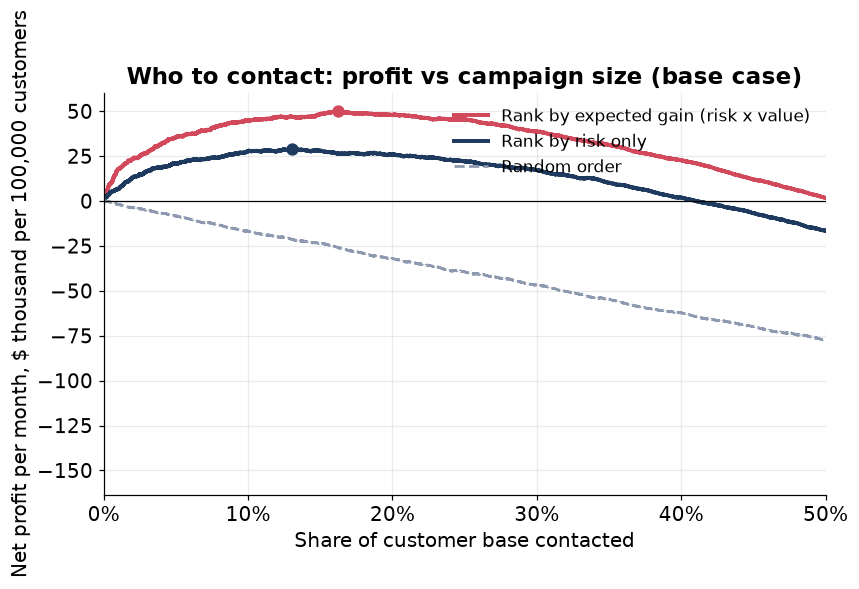

In [11]:
def profit_curve(score, pi=BASE["pi"]):
    o = np.argsort(-score)
    w = np.where(yte == 1, pi / rho_te, (1 - pi) / (1 - rho_te)); scale = 100000 / w.sum(); d = BASE["d"]
    gain_i = np.where(yte == 1, BASE["gamma"] * (clv_te - d) - BASE["f"], -(BASE["alpha"] * d + BASE["f"]))
    return np.cumsum((gain_i * w * scale)[o]), np.cumsum((w * scale)[o]) / 1e5

curves = {"Rank by expected gain (risk x value)": gain_b, "Rank by risk only": p_true_b}
fig, ax = plt.subplots(figsize=(8, 4.8))
for (lab, sc), c in zip(curves.items(), [RED, NAVY]):
    cum, fr = profit_curve(sc); ax.plot(fr, cum / 1000, color=c, lw=2.6, label=lab)
    k = int(np.argmax(cum)); ax.scatter(fr[k], cum[k] / 1000, color=c, zorder=5, s=50)
rng3 = np.random.default_rng(3); cum, fr = profit_curve(rng3.random(len(yte))); ax.plot(fr, cum / 1000, color=GREY, lw=1.8, ls="--", label="Random order")
ax.axhline(0, color="k", lw=0.8); ax.set_xlim(0, 0.5); ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Share of customer base contacted"); ax.set_ylabel("Net profit per month, $ thousand per 100,000 customers")
ax.set_title("Who to contact: profit vs campaign size (base case)"); ax.legend(loc="upper right", fontsize=11)
savefig("fig_profit_curve")
R["profit_curve_max"] = {lab: float(np.max(profit_curve(sc)[0])) for lab, sc in curves.items()}

### 7.4 Sensitivity: which assumptions matter?
Offer *leakage* (`alpha`, non-churners who also claim the offer) and offer success (`gamma`) are the two quantities Company A
can influence through offer design and should measure in a pilot. The second grid varies the true churn rate and customer value.

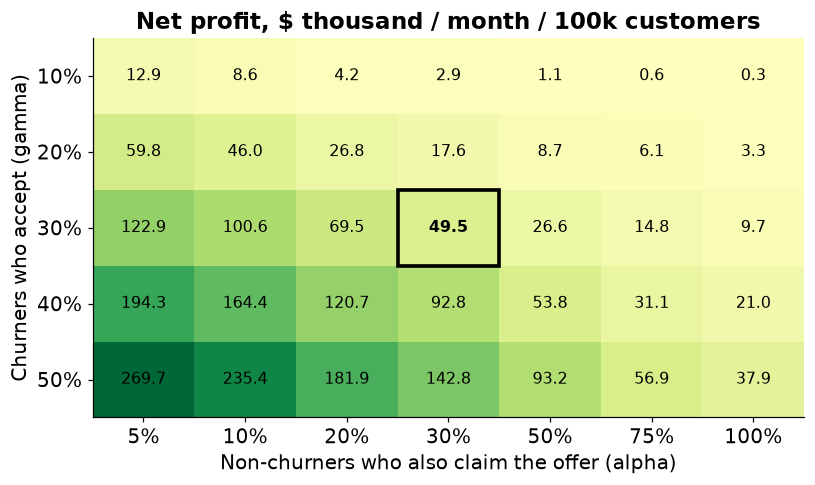

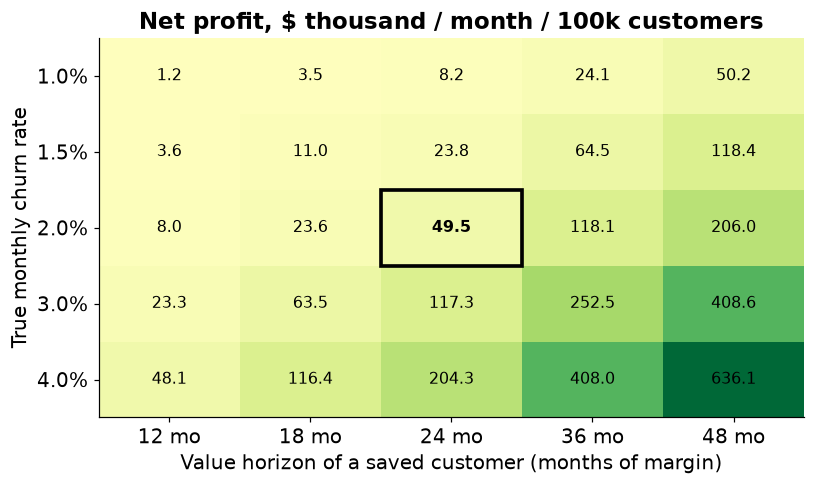

profit with literature worst case alpha=100%: 9686
Pessimistic {'profit': 89.7, 'spend': 124.1, 'roi': 0.7, 'contacts': 21.7, 'churners_reached': 2.1, 'saved': 0.4, 'churners_total': 1000.0}
Base {'profit': 49525.7, 'spend': 66555.3, 'roi': 0.7, 'contacts': 16638.8, 'churners_reached': 639.0, 'saved': 191.7, 'churners_total': 2000.0}
Upside {'profit': 164355.8, 'spend': 110754.0, 'roi': 1.5, 'contacts': 53194.5, 'churners_reached': 1455.0, 'saved': 582.0, 'churners_total': 2000.0}


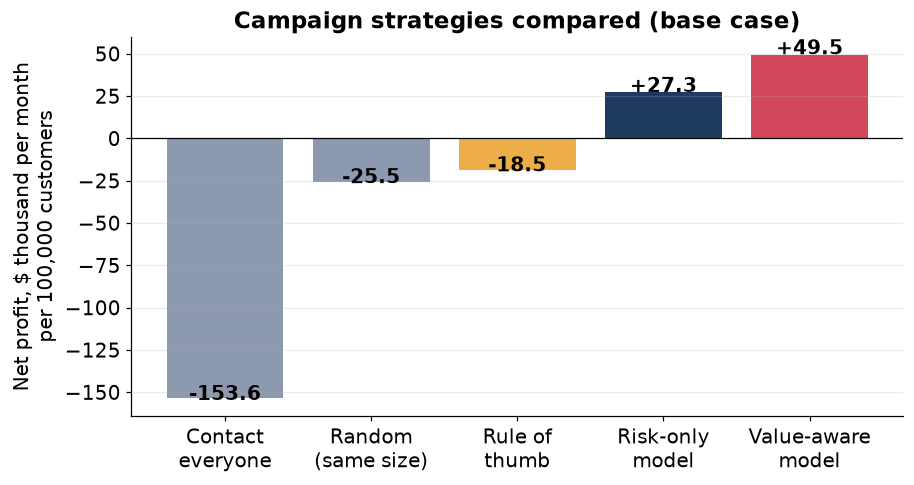

In [12]:
alphas = [0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]; gammas = [0.1, 0.2, 0.3, 0.4, 0.5]
S1 = np.array([[strategies(**{**BASE, "alpha": a, "gamma": g})[0]["Value-aware model (contact if expected gain > 0)"]["profit"] for a in alphas] for g in gammas])
pis = [0.01, 0.015, 0.02, 0.03, 0.04]; horizons = [12, 18, 24, 36, 48]; mults = [h / 24 for h in horizons]
S2 = np.array([[strategies(**{**BASE, "pi": p, "clv_mult": m})[0]["Value-aware model (contact if expected gain > 0)"]["profit"] for m in mults] for p in pis])
R["sens1"] = {"alphas": alphas, "gammas": gammas, "profit": S1.round(0).tolist()}
R["sens2"] = {"pis": pis, "horizons": horizons, "profit": S2.round(0).tolist()}


def heat_plot(M, xl, yl, xt, yt, ttl, name, base_xy):
    fig, ax = plt.subplots(figsize=(7.6, 4.6)); lim = np.abs(M).max()
    im = ax.imshow(M / 1000, cmap="RdYlGn", vmin=-lim / 1000, vmax=lim / 1000, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(len(xt))); ax.set_xticklabels(xt); ax.set_yticks(range(len(yt))); ax.set_yticklabels(yt)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j] / 1000:.1f}", ha="center", va="center", fontsize=10.5, fontweight="bold" if (i, j) == base_xy else None)
    ax.add_patch(plt.Rectangle((base_xy[1] - .5, base_xy[0] - .5), 1, 1, fill=False, ec="k", lw=2.4))
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(ttl); savefig(name)


heat_plot(S1, "Non-churners who also claim the offer (alpha)", "Churners who accept (gamma)", [f"{a:.0%}" for a in alphas], [f"{g:.0%}" for g in gammas],
          "Net profit, $ thousand / month / 100k customers", "fig_sens_alpha_gamma", (gammas.index(0.3), alphas.index(0.3)))
heat_plot(S2, "Value horizon of a saved customer (months of margin)", "True monthly churn rate", [f"{h} mo" for h in horizons], [f"{p:.1%}" for p in pis],
          "Net profit, $ thousand / month / 100k customers", "fig_sens_pi_clv", (pis.index(0.02), horizons.index(24)))

# break-even leakage in the base case
a_grid = np.linspace(0.01, 1.0, 100)
pr = [strategies(**{**BASE, "alpha": a})[0]["Value-aware model (contact if expected gain > 0)"]["profit"] for a in a_grid]
R["alpha_at_literature_worst_case"] = float(strategies(**{**BASE, "alpha": 1.0})[0]["Value-aware model (contact if expected gain > 0)"]["profit"])
R["blanket_all_profit"] = R["strategies_base"]["Contact everyone"]["profit"]
print("profit with literature worst case alpha=100%:", round(R["alpha_at_literature_worst_case"]))

# scenario table used on the slides
SCEN = {"Pessimistic": dict(alpha=0.5, gamma=0.2, pi=0.01, clv_mult=0.5), "Base": {}, "Upside": dict(alpha=0.1, gamma=0.4)}
R["scenarios"] = {}
for nm, ov in SCEN.items():
    s = strategies(**{**BASE, **ov})[0]["Value-aware model (contact if expected gain > 0)"]
    R["scenarios"][nm] = {**{k: float(v) for k, v in s.items()}, "params": {**BASE, **ov}}
    print(nm, {k: round(v, 1) for k, v in s.items()})

# bar chart of strategies for the slide
names = ["Contact everyone", "Random contact (same list size)", "Rule of thumb (tenure 10-12 mo or handset 300-420 d)",
         "Risk-only model (contact if p > break-even)", "Value-aware model (contact if expected gain > 0)"]
short = ["Contact\neveryone", "Random\n(same size)", "Rule of\nthumb", "Risk-only\nmodel", "Value-aware\nmodel"]
vals = [strat[n]["profit"] / 1000 for n in names]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
bars = ax.bar(short, vals, color=[GREY, GREY, GOLD, NAVY, RED])
for b, v, n in zip(bars, vals, names):
    ax.text(b.get_x() + b.get_width() / 2, v + (0.25 if v >= 0 else -0.9), f"{v:+.1f}", ha="center", fontweight="bold")
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("Net profit, $ thousand per month\nper 100,000 customers"); ax.set_title("Campaign strategies compared (base case)")
ax.grid(axis="x", visible=False)
savefig("fig_strategies")

## 8. Export
All the numbers used in the presentation are saved to `outputs/results.json`. The hold-out predictions and the customer
list for the base-case campaign are saved too, so they can be inspected.

In [13]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else float(o)
    if isinstance(o, (np.integer,)): return int(o)
    return o

(OUT / "results.json").write_text(json.dumps(clean(R), indent=2))
pd.DataFrame({"Customer_ID": df.Customer_ID.values[idx_te], "churn": yte, "p_model": p_hold, "p_true_2pct": p_true_b, "clv": clv_te,
              "expected_gain": gain_b, "contact": gain_b > 0}).sort_values("expected_gain", ascending=False).to_csv(OUT / "holdout_scores.csv", index=False)
print("saved", OUT / "results.json")

saved outputs\results.json
